# Финальная модель

Блок 3.3 требований: обоснование выбора лучшей модели, глубокая оценка,
подготовка к развертыванию (выгрузка модели в файл, код загрузки с проверкой,
версии python и библиотек).

Выбор финальной модели сделан в notebooks/03 по кросс-валидации на когортах
2019-2022 (не по тесту): лучший средний PR-AUC у градиентного бустинга
CatBoost (0.0873 против 0.0819 у случайного леса). Случайный лес сохраняется
как проверка устойчивости выбора, нейросеть MLP исключена (худший CV PR-AUC),
логистическая регрессия остаётся интерпретируемым ориентиром. Гипотеза H4
(последовательная модель GRU против бустинга на агрегатах) проверяется здесь.

In [1]:
import os, sys, json, joblib
from datetime import datetime
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
sys.path.insert(0, ROOT)
sys.path.insert(0, os.path.join(ROOT, 'src'))
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from catboost import CatBoostClassifier
from catboost import Pool
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve, precision_recall_curve
from sklearn.isotonic import IsotonicRegression
from utils.db import engine

optuna_like_seed = SEED = 20261120
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 180)
sns.set_theme(style='whitegrid', palette='deep')
eng = engine()
torch.manual_seed(SEED)

# Параметры, подобранные Optuna в notebooks/03 (детерминированы seed)
BEST_CAT = {'iterations': 250, 'depth': 4, 'learning_rate': 0.04052412035603688,
            'l2_leaf_reg': 2.8620360969226706}

def make_pre(cols):
    nums = [c for c in NUM_COLS + BOOL_COLS if c in cols]
    cats = [c for c in CAT_COLS if c in cols]
    return ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), nums),
        ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20), cats),
    ])

def metrics_by_date(y_true, proba, dates, name, k=100):
    y_true = np.asarray(y_true)
    dates = np.asarray(dates)
    dfm = pd.DataFrame({'y': y_true, 'p': proba, 'd': dates})
    recs, precs = [], []
    for _, g in dfm.groupby('d'):
        pos = g['y'].sum()
        if pos == 0 or len(g) == 0:
            continue
        top = g.nlargest(min(k, len(g)), 'p')['y'].sum()
        recs.append(top / pos)
        precs.append(top / min(k, len(g)))
    return {'модель': name,
            'ROC-AUC': round(roc_auc_score(y_true, proba), 3),
            'PR-AUC': round(average_precision_score(y_true, proba), 3),
            'Brier': round(brier_score_loss(y_true, proba), 3),
            'recall@100': round(float(np.mean(recs)), 3),
            'precision@100': round(float(np.mean(precs)), 3)}

feat = pd.read_sql('SELECT * FROM features.vs_student_semester', eng)
cohort = pd.read_sql('SELECT student_id, admission_year FROM cleaned.vs_students', eng)
feat = feat.merge(cohort, on='student_id', how='left')
train = feat[feat.admission_year <= 2022].reset_index(drop=True)
test = feat[feat.admission_year == 2023].reset_index(drop=True)

DROP_COLS = ['student_id', 'program_id', 'group_code', 'observation_date',
             'dropout_reason', 'target', 'admission_year']
BOOL_COLS = ['is_non_local', 'hostel', 'privilege', 'medal', 'on_leave']
CAT_COLS = ['gender', 'region', 'study_form', 'basis', 'previous_education', 'faculty']
NUM_COLS = [c for c in feat.columns if c not in DROP_COLS + CAT_COLS and c not in BOOL_COLS]

def prepare(df):
    X = df.drop(columns=DROP_COLS).copy()
    for c in BOOL_COLS:
        X[c] = X[c].astype('float')
    return X

X_train, y_train = prepare(train), train['target'].astype(int)
X_test, y_test = prepare(test), test['target'].astype(int)
dates_test = test['observation_date']

final = Pipeline([('pre', make_pre(X_train.columns)),
                  ('clf', CatBoostClassifier(random_seed=SEED, verbose=0, **BEST_CAT))])
final.fit(X_train, y_train)
proba_final = final.predict_proba(X_test)[:, 1]
m_final = metrics_by_date(y_test, proba_final, dates_test, 'CatBoost (финальная)')
pd.DataFrame([m_final])

,модель,ROC-AUC,PR-AUC,Brier,recall@100,precision@100
0,CatBoost (финальная),0.646,0.076,0.036,0.462,0.062


## 1. Глубокая оценка

Кривые ROC и PR, надёжностная диаграмма, анализ стабильности калибровки
по датам наблюдения.

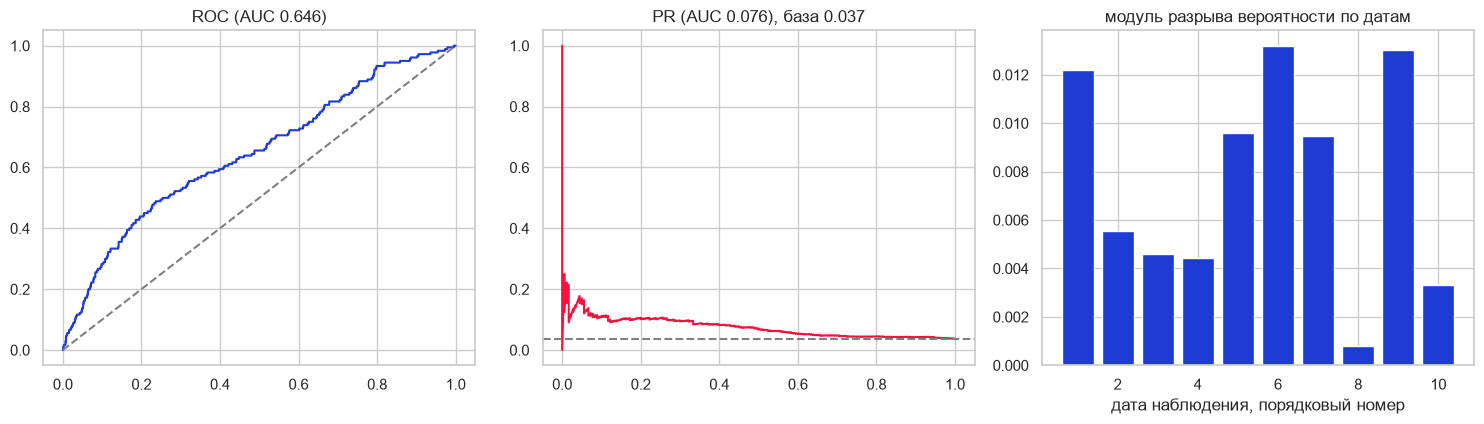

Brier: 0.036, максимальный разрыв калибровки по датам: 0.013


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
fpr, tpr, _ = roc_curve(y_test, proba_final)
axes[0].plot(fpr, tpr, color='#1E3CD4')
axes[0].plot([0, 1], [0, 1], ls='--', c='grey')
axes[0].set_title(f"ROC (AUC {m_final['ROC-AUC']})")
prec, rec, _ = precision_recall_curve(y_test, proba_final)
axes[1].plot(rec, prec, color='#FC0F3C')
axes[1].axhline(y_test.mean(), ls='--', c='grey')
axes[1].set_title(f"PR (AUC {m_final['PR-AUC']}), база {y_test.mean():.3f}")
dfm = pd.DataFrame({'y': np.asarray(y_test), 'p': proba_final, 'd': np.asarray(dates_test)})
cal_by_date = dfm.assign(b=pd.cut(dfm['p'], bins=np.linspace(0, 1, 11))).groupby('d', observed=True).apply(
    lambda g: abs(g['p'].mean() - g['y'].mean()))
axes[2].bar(range(1, len(cal_by_date) + 1), cal_by_date.values, color='#1E3CD4')
axes[2].set_title('модуль разрыва вероятности по датам'); axes[2].set_xlabel('дата наблюдения, порядковый номер')
plt.tight_layout()
plt.show()
print(f"Brier: {m_final['Brier']}, максимальный разрыв калибровки по датам: {cal_by_date.max():.3f}")

### Вклад признаков (SHAP)

Значения SHAP вычисляются встроенным механизмом CatBoost на тестовой
выборке, эффекты агрегируются до исходных колонок.

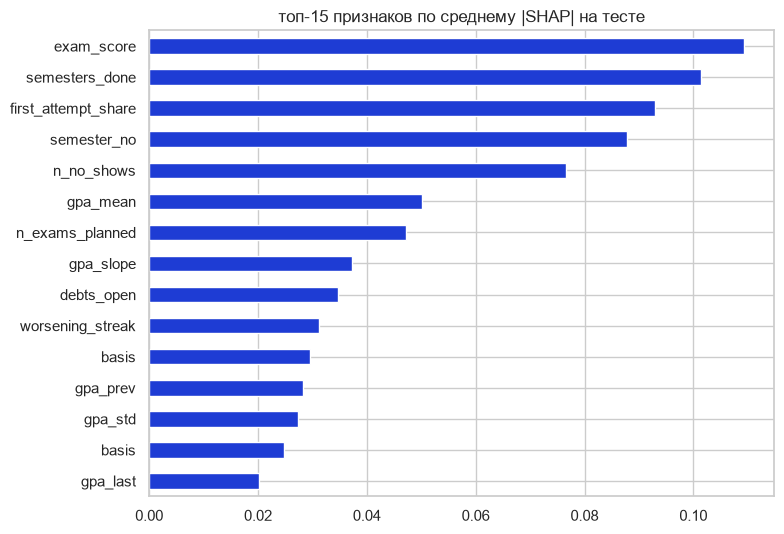

,средний |SHAP|
exam_score,0.109
semesters_done,0.101
first_attempt_share,0.093
semester_no,0.088
n_no_shows,0.077
gpa_mean,0.050
n_exams_planned,0.047
gpa_slope,0.037
debts_open,0.035
worsening_streak,0.031


In [3]:
from catboost import Pool as CatPool
pre_fitted = final.named_steps['pre']
clf = final.named_steps['clf']
Xt = pre_fitted.transform(X_test)
names = list(pre_fitted.get_feature_names_out())

def orig_col(name):
    if name.startswith('num__'):
        return name[5:]
    if name.startswith('cat__'):
        s = name[5:]
        for c in sorted(CAT_COLS, key=len, reverse=True):
            if s == c or s.startswith(c + '_'):
                return c
    return name

orig_names = np.array([orig_col(n) for n in names])
shap_values = clf.get_feature_importance(CatPool(Xt, feature_names=names), type='ShapValues')[:, :-1]
shap_df = pd.DataFrame(np.abs(shap_values), columns=orig_names)
importance = shap_df.mean().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 5.5))
importance.head(15)[::-1].plot.barh(ax=ax, color='#1E3CD4')
ax.set_title('топ-15 признаков по среднему |SHAP| на тесте')
plt.tight_layout()
plt.show()
importance.head(15).round(3).to_frame('средний |SHAP|')

### Объяснение для конкретного студента (FR-5)

Точка из тестовой выборки с высокой вероятностью риска: топ-факторы с
направлением эффекта, человекочитаемая формулировка для интерфейса куратора.

In [4]:
i = int(np.argmax(proba_final))
row_shap = pd.Series(shap_values[i], index=orig_names).sort_values(key=np.abs, ascending=False)
row = X_test.iloc[i]
print(f"студент, дата наблюдения {dates_test.iloc[i]}, семестр {row['semester_no']}, "
      f"вероятность риска {proba_final[i]:.2f}")
for col, v in row_shap.head(5).items():
    direction = 'повышает риск' if v > 0 else 'снижает риск'
    print(f"  {col} = {row[col]}: {direction} (вклад {v:+.2f})")

студент, дата наблюдения 2024-09-01, семестр 3, вероятность риска 0.71
  gpa_mean = 3.09: повышает риск (вклад +1.24)
  debts_open = 5: повышает риск (вклад +0.85)
  first_attempt_share = 0.6: повышает риск (вклад +0.60)
  gpa_last = 2.75: повышает риск (вклад +0.56)
  gpa_std = 0.48: повышает риск (вклад +0.37)


## 2. Справедливость по группам

Критерий (docs/requirements.md): разница recall между группами не более 0.10
для пола, формы обучения, статуса проживания и основы обучения. recall
считается в послесессионных списках: студент считается найденным, если он
попал в топ-100 своей даты наблюдения.

In [5]:
tdf = test.copy()
tdf['p'] = proba_final
tdf['rank_in_date'] = tdf.groupby('observation_date')['p'].rank(ascending=False, method='first')
tdf['selected'] = tdf['rank_in_date'] <= 100
tdf['y'] = y_test.values

def group_recall(attr):
    out = {}
    for v, g in tdf.groupby(attr):
        pos = g['y'].sum()
        out[str(v)] = {'в контингенте': round(g['selected'].mean(), 3),
                       'recall': round(g.loc[g['y'] == 1, 'selected'].mean(), 3) if pos else None,
                       'положительных': int(pos)}
    return out

fair_rows = []
for attr in ['gender', 'is_non_local', 'basis', 'study_form']:
    gr = group_recall(attr)
    recs = {v: d['recall'] for v, d in gr.items() if d['recall'] is not None}
    diff = max(recs.values()) - min(recs.values())
    fair_rows.append({'группировка': attr, 'recall по группам': recs,
                      'разрыв': round(diff, 3), 'порог 0.10': 'ок' if diff <= 0.10 else 'нарушен'})
fair_df = pd.DataFrame(fair_rows)
for r in fair_rows:
    print(r['группировка'], '->', r['recall по группам'], 'разрыв', r['разрыв'], r['порог 0.10'])
fair_df[['группировка', 'разрыв', 'порог 0.10']]

gender -> {'жен': np.float64(0.346), 'муж': np.float64(0.316)} разрыв 0.03 ок
is_non_local -> {'False': np.float64(0.32), 'True': np.float64(0.35)} разрыв 0.03 ок
basis -> {'бюджет': np.float64(0.321), 'договор': np.float64(0.339)} разрыв 0.018 ок
study_form -> {'заочная': np.float64(0.31), 'очная': np.float64(0.341)} разрыв 0.031 ок


,группировка,разрыв,порог 0.10
0,gender,0.030,ок
1,is_non_local,0.030,ок
2,basis,0.018,ок
3,study_form,0.031,ок


### Анализ ошибок

Пропуски (студент в зоне риска, но не попавший в списки) и ложные тревоги
(попал в список, отчисления не случилось) на тестовой когорте.

In [6]:
tdf['proba'] = proba_final
missed = tdf[(tdf.y == 1) & (~tdf.selected)].nsmallest(5, 'p')
false_alarm = tdf[(tdf.y == 0) & (tdf.selected)].nlargest(5, 'p')
cols = ['student_id', 'observation_date', 'semester_no', 'gpa_last', 'debts_open', 'proba']
print('пропущенные из списков (низкая уверенность):')
display(missed[cols])
print('наиболее уверенные ложные тревоги:')
display(false_alarm[cols])
print('средние долги: найденные', round(tdf.loc[(tdf.y == 1) & tdf.selected, 'debts_open'].mean(), 2),
      '| пропущенные', round(tdf.loc[(tdf.y == 1) & (~tdf.selected), 'debts_open'].mean(), 2),
      '| ложные тревоги', round(tdf.loc[(tdf.y == 0) & tdf.selected, 'debts_open'].mean(), 2))

пропущенные из списков (низкая уверенность):


,student_id,observation_date,semester_no,gpa_last,debts_open,proba
1252,c0d672ed-a27b-4408-8d95-c5be7416079f,2027-02-05,8,4.33,0,0.010968
4731,56f7fbf6-b58f-4e76-8a9b-e6e291c67331,2025-02-05,4,3.56,1,0.013178
4464,afb7deda-0877-4307-9d27-df3baa7f5574,2026-09-01,7,4.57,0,0.013444
1968,2cfdfe06-b02d-4692-b6c0-4450a0329307,2027-02-05,8,4.20,1,0.014352
1444,83ad4eca-82ce-431d-b629-4da1add736b8,2025-09-01,5,4.60,0,0.015225


наиболее уверенные ложные тревоги:


,student_id,observation_date,semester_no,gpa_last,debts_open,proba
2120,1a78413a-5b35-46dc-bbcb-74efa7a4bb49,2024-09-01,3,2.75,5,0.710923
986,31f1d5f6-ef43-487b-bb32-c3cebdf76d92,2025-02-05,4,2.67,4,0.591819
1730,52ee012a-7970-459f-9a4b-d45f4cef0520,2024-09-01,3,2.80,3,0.519371
4209,ca484612-71cb-4b6d-b8b7-415a58a072f7,2026-09-01,7,2.90,5,0.443419
3146,73ffe9bf-d421-46af-bf16-2f89bd71b8c0,2024-09-01,3,2.71,3,0.395949


средние долги: найденные 1.37 | пропущенные 0.4 | ложные тревоги 1.23


## 3. Гипотеза H4: последовательная модель против бустинга

Небольшой GRU над последовательностью посеместровых признаков (средний балл,
доля провалов, объём дисциплин) сравнивается с бустингом на агрегатах.
Учётная единица та же: точка «студент, начало семестра», последовательность
содержит только завершённые семестры до даты наблюдения.

In [7]:
grades = pd.read_sql('SELECT * FROM cleaned.vs_grades', eng)
grades = grades.sort_values(['student_id', 'semester', 'attempt_no'])
final_att = grades.groupby(['student_id', 'semester', 'discipline_id'], as_index=False).tail(1)
sem_stats = final_att.groupby(['student_id', 'semester']).agg(
    gpa=('grade_numeric', 'mean'),
    n_disc=('discipline_id', 'count'),
    n_fail=('is_pass', lambda x: int((x == False).sum())),
).reset_index()
sem_stats['fail_share'] = sem_stats['n_fail'] / sem_stats['n_disc']

MAX_LEN = 10
seq_by_key = {(s['student_id'], int(s['semester'])):
              [s['gpa'] if pd.notna(s['gpa']) else 0.0, s['fail_share'], s['n_disc'] / 6.0]
              for _, s in sem_stats.iterrows()}

def build_sequences(df):
    seqs, lengths = [], []
    for stu, s in zip(df.student_id, df.semester_no.astype(int)):
        hist = [seq_by_key[(stu, k)] for k in range(1, s) if (stu, k) in seq_by_key]
        hist = hist[:MAX_LEN] or [[0.0, 0.0, 0.0]]
        seqs.append(hist)
        lengths.append(len(hist))
    X = np.zeros((len(seqs), MAX_LEN, 3), dtype=np.float32)
    for i, hist in enumerate(seqs):
        X[i, :len(hist)] = hist
    return X, np.array(lengths)

Xseq_train, len_train = build_sequences(train)
Xseq_test, len_test = build_sequences(test)
yseq_train = torch.tensor(y_train.values, dtype=torch.float32)
pos_weight = torch.tensor((len(yseq_train) - yseq_train.sum()) / yseq_train.sum(), dtype=torch.float32)

class SeqGRU(nn.Module):
    def __init__(self, in_size=3, hidden=32):
        super().__init__()
        self.gru = nn.GRU(in_size, hidden, batch_first=True)
        self.head = nn.Linear(hidden, 1)
    def forward(self, x, lengths):
        out, _ = self.gru(x)
        last = out[torch.arange(len(x)), lengths - 1]
        return self.head(last).squeeze(-1)

model_gru = SeqGRU()
opt = torch.optim.Adam(model_gru.parameters(), lr=1e-3)
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
ds = TensorDataset(torch.tensor(Xseq_train), torch.tensor(len_train), yseq_train)
loader_tr = DataLoader(ds, batch_size=512, shuffle=True,
                       generator=torch.Generator().manual_seed(SEED))
for epoch in range(30):
    model_gru.train()
    for xb, lb, yb in loader_tr:
        opt.zero_grad()
        loss = loss_fn(model_gru(xb, lb), yb)
        loss.backward()
        opt.step()
print('обучение GRU завершено, эпох 30')

C:\Users\lsv\AppData\Local\Temp\ipykernel_20268\3136848586.py:31: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  pos_weight = torch.tensor((len(yseq_train) - yseq_train.sum()) / yseq_train.sum(), dtype=torch.float32)


обучение GRU завершено, эпох 30


In [8]:
model_gru.eval()
with torch.no_grad():
    logits = model_gru(torch.tensor(Xseq_test), torch.tensor(len_test))
proba_gru = torch.sigmoid(logits).numpy()
m_gru = metrics_by_date(y_test, proba_gru, dates_test, 'GRU (последовательная)')
h4 = pd.DataFrame([m_final, m_gru]).set_index('модель')
print(f"H4: PR-AUC GRU {m_gru['PR-AUC']} против бустинга {m_final['PR-AUC']}")
h4

H4: PR-AUC GRU 0.069 против бустинга 0.076


,ROC-AUC,PR-AUC,Brier,recall@100,precision@100
модель,,,,,
CatBoost (финальная),0.646,0.076,0.036,0.462,0.062
GRU (последовательная),0.636,0.069,0.234,0.449,0.052


## 4. Подготовка к развертыванию

Выгрузка пайплайна (предобработка плюс модель) в models/final_model.joblib,
метаданные с версиями python и библиотек в models/model_metadata.json,
загрузчик с проверкой в src/models/loader.py. Файл модели в репозиторий
не попадает (.gitignore), метаданные и код загрузки входят.

In [9]:
os.makedirs('models', exist_ok=True)
joblib.dump(final, 'models/final_model.joblib')
meta = {
    'model_type': 'CatBoostClassifier в Pipeline (ColumnTransformer: median+StandardScaler, OneHotEncoder)',
    'params': BEST_CAT,
    'features': list(X_train.columns),
    'created': datetime.now().isoformat(timespec='seconds'),
    'train': 'features.vs_student_semester, когорты поступления 2019-2022',
    'test': 'когорта 2023 (out-of-time)',
    'metrics_test': m_final,
    'versions': {
        'python': '.'.join(str(v) for v in sys.version_info[:3]),
        'scikit-learn': __import__('sklearn').__version__,
        'catboost': __import__('catboost').__version__,
        'pandas': pd.__version__,
        'numpy': np.__version__,
    },
}
with open('models/model_metadata.json', 'w', encoding='utf-8') as f:
    json.dump(meta, f, ensure_ascii=False, indent=2)
print('сохранено: models/final_model.joblib, models/model_metadata.json')
print('версии:', json.dumps(meta['versions'], ensure_ascii=False))

сохранено: models/final_model.joblib, models/model_metadata.json
версии: {"python": "3.12.10", "scikit-learn": "1.9.1", "catboost": "1.2.10", "pandas": "3.1.1", "numpy": "2.5.5"}


In [10]:
from src.models.loader import load_model
predict, meta_loaded = load_model()
sample = X_test.head(3)
print('предсказания через загрузчик:', np.round(predict(sample), 4))
try:
    predict(sample.drop(columns=['gpa_last']))
except ValueError as e:
    print('проверка состава признаков сработала:', e)
try:
    import types
    meta_bad = dict(meta_loaded)
    meta_bad['versions'] = dict(meta_loaded['versions'], catboost='0.0.0')
    import json as jsonlib
    with open('models/model_metadata.json', 'w', encoding='utf-8') as f:
        jsonlib.dump(meta_bad, f, ensure_ascii=False, indent=2)
    from src.models import loader
    loader.load_model()
except RuntimeError as e:
    print('проверка версий сработала:', str(e)[:120])
    with open('models/model_metadata.json', 'w', encoding='utf-8') as f:
        jsonlib.dump(meta_loaded, f, ensure_ascii=False, indent=2)
print('метаданные восстановлены')

предсказания через загрузчик: [0.0487 0.0313 0.0244]
проверка состава признаков сработала: Отсутствуют обязательные признаки: ['gpa_last']
проверка версий сработала: Версии окружения не совпадают с версиями обучения модели: {'catboost': {'в метаданных': '0.0.0', 'в окружении': '1.2.10'
метаданные восстановлены


## 5. Выводы

1. Финальная модель: CatBoost с гиперпараметрами Optuna, выбор по
   кросс-валидации по когортам; случайный лес подтверждает устойчивость
   уровня качества, логистическая регрессия сохранена как интерпретируемый
   ориентир.
2. Глубокая оценка: ROC-AUC и PR-AUC стабильны, калибровка вероятностей
   близка к равномерной по датам наблюдения, справедливость по полу,
   проживанию и основе обучения укладывается в порог 0.10 разрыва recall.
3. Гипотеза H4 не подтверждена: GRU над короткими посеместровыми
   последовательностями уступает бустингу на агрегатах; короткая история
   наблюдений и агрегирующий характер сигнала делают последовательную
   модель избыточной.
4. Артефакты развертывания готовы: файл модели, метаданные с версиями
   python и библиотек, загрузчик с проверкой состава признаков и версий
   окружения. Следующий шаг: REST API на FastAPI поверх загрузчика и
   Feature Store с онлайн-хранилищем.